In [1]:
#importing library
import numpy as np 
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import data_utils as du

In [2]:
#Importing the dataset
reg_path= "../../data/Regression_datasets/edtech.csv"
reg_data= pd.read_csv(reg_path)
print(reg_data.head())

   study_hours  attendance  quiz_score  final_score
0     4.861241   66.787390   73.925097   102.326773
1     7.867286   57.249407    9.283458   118.735663
2     4.930715   53.663533   31.008742    97.828323
3     5.973968   59.134309   99.558801   125.076944
4     6.887983   61.178486   61.428487   123.053748


In [3]:
#data exploration
du.data_exploration(reg_data)

DATA EXPLORATION
Shape of dataset: 10000 rows, 4 columns

Columns: ['study_hours', 'attendance', 'quiz_score', 'final_score']

Data Types:
 study_hours    float64
attendance     float64
quiz_score     float64
final_score    float64
dtype: object

Missing Values:
 study_hours    0
attendance     0
quiz_score     0
final_score    0
dtype: int64

Statistical Summary:
         study_hours    attendance    quiz_score   final_score
count  10000.000000  10000.000000  10000.000000  10000.000000
mean       4.986748     74.889255     50.374571    102.367783
std        2.011061     14.384455     29.020628     23.711740
min       -2.211836     50.005648      0.014798     14.571985
25%        3.614358     62.433670     25.529728     86.336130
50%        4.982182     74.751805     50.306719    102.607591
75%        6.358791     87.439232     75.627213    118.460803
max       13.038838     99.997412     99.998458    204.092058


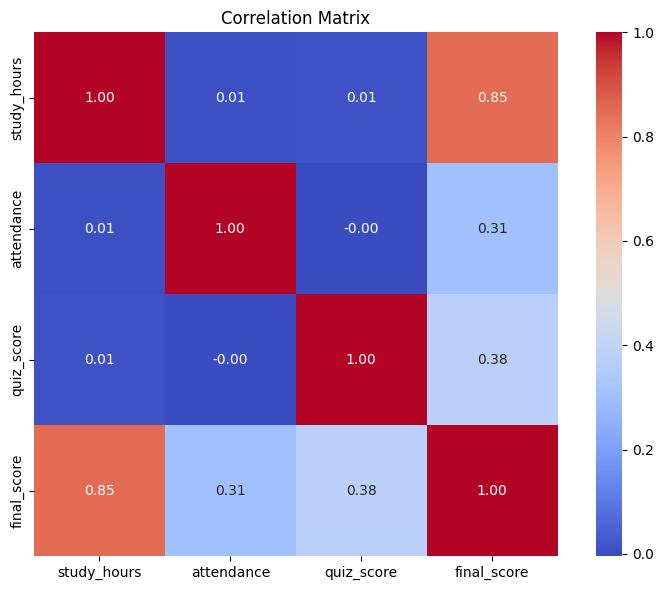

In [4]:
#data visualization
corr = du.get_correlation_matrix(reg_data)
du.plot_correlation_matrix(corr)

Studyhours 85% corelated to final score and attendence and quize score almost 31 and 38 percent related to final score.

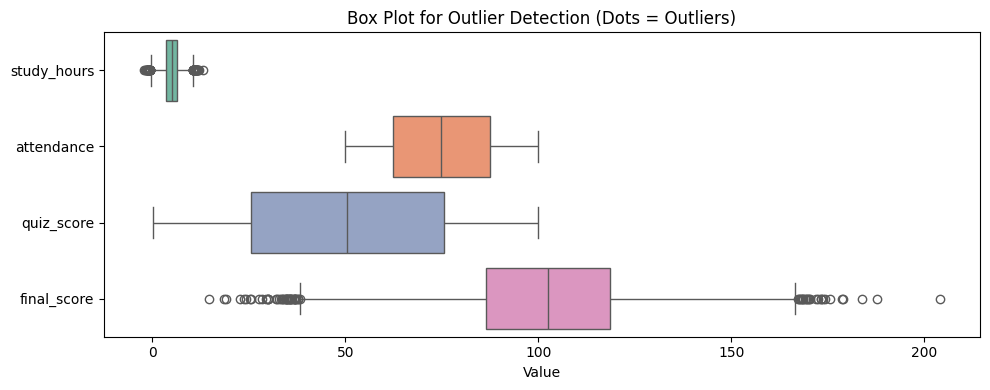

In [5]:
#check for outliers
cols = reg_data.columns
du.plot_boxplots(reg_data, cols)

In [6]:
#linear regression 
X = reg_data.drop('final_score', axis=1)
y = reg_data['final_score']

In [7]:
model, mse, r2, y_test, y_pred =    du.linear_regression_model(X, y)

Mean Squared Error: 25.5343
R-squared: 0.9531


/opt/anaconda3/envs/ai_env/lib/python3.10/site-packages/sklearn/linear_model/_base.py:280: RuntimeWarning: divide by zero encountered in matmul
  return X @ coef_ + self.intercept_
/opt/anaconda3/envs/ai_env/lib/python3.10/site-packages/sklearn/linear_model/_base.py:280: RuntimeWarning: overflow encountered in matmul
  return X @ coef_ + self.intercept_
/opt/anaconda3/envs/ai_env/lib/python3.10/site-packages/sklearn/linear_model/_base.py:280: RuntimeWarning: invalid value encountered in matmul
  return X @ coef_ + self.intercept_


In [8]:
du.cross_validation(model, X, y, cv=5)

5-Fold Cross-Validation (r2): [0.95746027 0.95387376 0.95608075 0.95327373 0.95374552]
Average CV score: 0.9549 (± 0.0016)


/opt/anaconda3/envs/ai_env/lib/python3.10/site-packages/sklearn/linear_model/_base.py:280: RuntimeWarning: divide by zero encountered in matmul
  return X @ coef_ + self.intercept_
/opt/anaconda3/envs/ai_env/lib/python3.10/site-packages/sklearn/linear_model/_base.py:280: RuntimeWarning: overflow encountered in matmul
  return X @ coef_ + self.intercept_
/opt/anaconda3/envs/ai_env/lib/python3.10/site-packages/sklearn/linear_model/_base.py:280: RuntimeWarning: invalid value encountered in matmul
  return X @ coef_ + self.intercept_
/opt/anaconda3/envs/ai_env/lib/python3.10/site-packages/sklearn/linear_model/_base.py:280: RuntimeWarning: divide by zero encountered in matmul
  return X @ coef_ + self.intercept_
/opt/anaconda3/envs/ai_env/lib/python3.10/site-packages/sklearn/linear_model/_base.py:280: RuntimeWarning: overflow encountered in matmul
  return X @ coef_ + self.intercept_
/opt/anaconda3/envs/ai_env/lib/python3.10/site-packages/sklearn/linear_model/_base.py:280: RuntimeWarning: i

array([0.95746027, 0.95387376, 0.95608075, 0.95327373, 0.95374552])

95% prediction accuracy can able to attain using this data


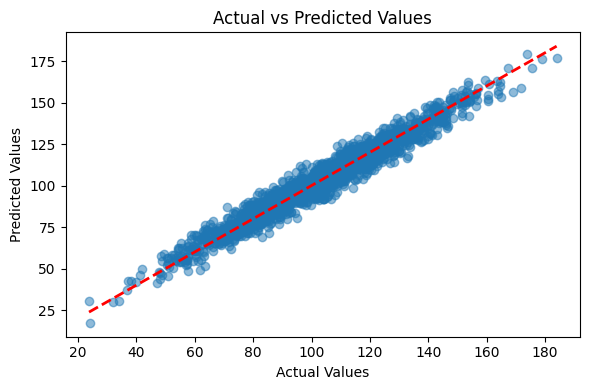

In [9]:
du.plot_actual_vs_predicted(y_test, y_pred)